# Step 5: co-expression of LIN28A, TTYH1 and NES (question 1, annotated version)

**Question 1:** in which cell types or states are the three genes co-expressed in the same single cell?

**Definitions**

- **Expressed:** at least 1 UMI of the gene in the cell (as in step 04).
- **Co-expressed / triple-positive:** all three genes expressed in the same cell.
- **Expected by chance:** the number of triple-positive cells a group would have if the three genes were
  switched on independently of each other.

**Why "expected" is needed.** A cell type where each gene is common will have many triple-positive cells just
by chance. Example: if 50% of cells express gene 1, 50% gene 2 and 50% gene 3, then with no link between the
genes 0.5 x 0.5 x 0.5 = 12.5% of cells are still triple-positive. Comparing observed with expected tells us
whether the genes really go together in the same cells, or only appear together because each is common.

**Replicates are donors.** Cells from the same embryo are not independent, so every number is computed per
donor and summarised over donors.

**Population for question 2:** at the end we pick the authors' clusters where triple-positive cells are
clearly enriched. Step 06 and 07 then find the markers of this population.

Output for step 06: `data/processed/population_clusters.txt`. Figures: `results/figures/05_*.png` (three)

*The outputs shown are from the run of 13 November 2026 on the full dataset. Running the notebook again
overwrites them with identical values.*

## Setup

**What this cell does**

- Same first lines as every notebook: move to the repository root and allow imports from `src/`.
- From `common.py`: the age bins, the config, the three genes, the `data/processed/` folder and the helpers.
- `MIN_CELLS = 50`: donor groups with fewer than 50 cells are left out, because a percentage from a handful of
  cells is mostly noise.
- `POP`: the population settings from `config.yaml`:
  - `chemistry: v3`: clusters are ranked on v3 cells only
  - `min_cells: 500`: a cluster needs at least 500 v3 cells to be considered
  - `fold: 5`: its share of triple-positive cells must be at least 5 times the dataset-wide share

In [1]:
# The notebooks live in notebooks/. Move to the repository root so config.yaml, data/ and results/
# are found, and make src/common.py importable.
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import BINS, CFG, GENES, PROCESSED, cell_table, open_braun, save

MIN_CELLS, POP = CFG["min_cells"], CFG["population"]

## Load the data

**What this cell does**

- Opens the h5ad and builds the per-cell table, as before.
- `pd.read_csv(PROCESSED / "gene_counts.csv.gz", index_col=0)` loads the three-gene counts saved by step 04.
  `index_col=0` uses the first column (the cell names) as row labels, so the rows line up with `cells`.
- `>= 1` turns the counts into True/False: expressed or not.
- `expressed.all(axis=1)` is True only when all three genes are True in that cell (`axis=1` means across the
  columns of one row). This new column `triple` marks the triple-positive cells.

In [2]:
adata = open_braun()
cells = cell_table(adata)
# Counts of the three genes from step 4, turned into yes/no per cell
expressed = pd.read_csv(PROCESSED / "gene_counts.csv.gz", index_col=0) >= 1
cells["triple"] = expressed.all(axis=1)

## Observed vs expected triple-positive cells per group

**Groups.** Every combination of cell
class, age bin, kit and donor is one group, e.g. *Radial glia, early, v3, donor XDD:313*.

**The depth problem.** A cell with many UMIs (deeply sequenced) detects more of every gene. If deep and shallow
cells are mixed in one group, the deep cells are more often positive for all three genes at once, simply
because they are deep. That looks like co-expression but is only depth. To avoid this, each group is split into
5 depth groups, the expectation is computed inside each and the results are added up.

**Toy example of the expectation.** A group has two depth levels with 100 cells each:

| Depth | Cells | % LIN28A | % TTYH1 | % NES | Expected triple-positive |
|---|---|---|---|---|---|
| shallow | 100 | 1% | 50% | 20% | 100 x 0.01 x 0.5 x 0.2 = 0.1 |
| deep | 100 | 4% | 90% | 60% | 100 x 0.04 x 0.9 x 0.6 = 2.16 |
| **total** | 200 | | | | **2.26** |

If this group really has 10 triple-positive cells, observed / expected = 10 / 2.26, about 4.4 times more than
chance: the genes go together. If it has 2, the ratio is about 0.9: what chance gives.

**What this cell does**

- `group`: the four columns that define a group.
- `d`: one table with the group columns, the cell's UMIs, `triple` and the three expressed columns.
- `d["depth"]`: the depth group of each cell, 1 to 5.
  - `groupby(group)["umis"].rank(pct=True)` ranks every cell's UMIs inside its own group as a fraction
    between 0 and 1 (the shallowest cell near 0, the deepest at 1)
  - `* 5` and `np.ceil` (round up) turn that into 1, 2, 3, 4 or 5: the depth quintile
- `strata`: the cells grouped by group and depth quintile.
- `expected`:
  - `strata[GENES].mean()` is the detection rate of each gene in each stratum (the mean of True/False)
  - `.prod(axis=1)` multiplies the three rates: the chance that a cell has all three if they are independent
  - `* strata.size()` turns that chance into a number of cells
  - `.groupby(level=group).sum()` adds the 5 depth strata back into one expected count per group
- `per_donor`: per group, the number of cells (`size`) and the observed triple-positive cells (`sum` of True).
- `triple_pct`: observed / cells x 100, the share of triple-positive cells.
- `log2_oe`: log2 of observed / expected.
  - 0 means as expected by chance, +1 means twice as many as chance, -1 means half
  - `+ 0.5` on both sides avoids dividing by zero or taking log(0) when a group has no triple-positive
    cells. A side effect: groups where both observed and expected are near 0 get a value near 0
- The last line keeps only groups with at least 50 cells.

In [3]:
# A cell class can have many triple-positive cells only because it expresses each gene a lot.
# Comparing with the independence expectation shows whether the three genes go together more
# than chance would give.
group = ["cell_class", "age_bin", "chemistry", "donor"]
d = cells[group + ["umis", "triple"]].join(expressed)
# Depth group 1 to 5 inside each group, so shallow and deep cells are compared with their own kind
d["depth"] = np.ceil(d.groupby(group)["umis"].rank(pct=True) * 5)
strata = d.groupby(group + ["depth"])
# expected = cells in the depth group x product of the three detection rates, summed over depth groups
expected = (strata.size() * strata[GENES].mean().prod(axis=1)).groupby(level=group).sum()
per_donor = d.groupby(group).agg(cells=("triple", "size"), observed=("triple", "sum"))
per_donor["expected"] = expected
per_donor["triple_pct"] = 100 * per_donor["observed"] / per_donor["cells"]
# +0.5 avoids log(0) when a group has no triple-positive cells
per_donor["log2_oe"] = np.log2((per_donor["observed"] + 0.5) / (per_donor["expected"] + 0.5))
per_donor = per_donor[per_donor["cells"] >= MIN_CELLS].reset_index()

## Summary per cell class (v3, early bin)

**What this cell does**

- `v3`: only the v3 groups. v3 detects more molecules per cell (step 02), so v2 and v3 groups would not be
  comparable. v3 is the better kit for finding a rare three-gene combination.
- `summary`: per age bin and cell class:
  - `donors`: the number of donors with at least 50 cells of that class
  - `triple_pct` and `log2_oe`: the **median over donors**. The median is used instead of the mean, so one
    unusual embryo cannot pull the summary.
- The print shows the early bin, sorted by `triple_pct`. Early is where LIN28A is still expressed (step 04).
  `.round(2)` keeps two decimals.

In [4]:
# Summary on v3 only: v3 detects more genes per cell, so mixing kits would blur the ranking
v3 = per_donor[per_donor["chemistry"] == "v3"]
summary = v3.groupby(["age_bin", "cell_class"]).agg(donors=("donor", "size"), triple_pct=("triple_pct", "median"),
                                                     log2_oe=("log2_oe", "median"))
print("v3, median over donors:\n", summary.loc[BINS[0]].sort_values("triple_pct", ascending=False).round(2))

v3, median over donors:
               donors  triple_pct  log2_oe
cell_class
Neural crest       2        1.30     0.10
Radial glia        6        0.59     0.05
Neuronal IPC       6        0.44     0.28
Placodes           2        0.18    -0.19
Neuroblast         6        0.06     0.44
Neuron             6        0.03     0.45
Fibroblast         2        0.01    -1.16
Glioblast          2        0.00     0.00
Erythrocyte        5        0.00     0.00
Immune             5        0.00     0.00
Vascular           6        0.00     0.00


**Reading the output (early bin, v3)**

- **Where triple-positive cells are most frequent:** neural crest (1.30%, but only 2 donors), radial glia
  (0.59%, 6 donors) and neuronal intermediate progenitors (IPC, 0.44%, 6 donors). These match the cell types
  where step 04 found high TTYH1 and NES plus some LIN28A.
- **Observed vs expected:** radial glia have log2_oe = 0.05, practically 0. So in radial glia the three genes
  are found together about as often as their separate detection rates predict. The co-expression is real, but
  it comes from TTYH1 and NES being very common plus the rare LIN28A, not from the three genes being switched
  on together in a special subset of cells.
- Neuronal IPC (0.28) and neural crest (0.10) are slightly above chance.
- Neuroblasts and neurons have higher ratios (0.44, 0.45), but they have almost no triple-positive cells
  (0.06% and 0.03%), so these ratios rest on very few cells.
- Glioblasts, blood, immune and vascular cells: no triple-positive cells. Their log2_oe of 0 is the +0.5
  side effect described above (0 observed, about 0 expected), not "as expected".

## Population: clusters enriched for triple-positive cells

**Why clusters:** cell classes are broad
(all radial glia from 5 to 14 weeks and all brain regions are one class). The authors' clusters are finer
(about 600). Choosing at cluster level gives a more specific cell state for the marker search.

**What this cell does**

- `ref`: all v3 cells.
- `background`: the share of triple-positive cells among all v3 cells. This is the baseline to compare against.
- `clusters`: one row per cluster with
  - `cells`: number of v3 cells
  - `triple`: share of triple-positive cells
  - `age`: median age of its cells
  - `cell_class` and `region`: the most common value in the cluster (`x.mode()[0]`: the mode is the most
    frequent value; `[0]` takes the first if there is a tie)
- `selected`: True when the cluster has at least 500 v3 cells **and** a triple-positive share of at least
  5 x background. The size rule stops tiny clusters with a few lucky cells from being picked.
- `chosen`: the IDs of the selected clusters, written to `population_clusters.txt` for step 06.
- `in_pop`: True for **all** cells of these clusters, from both kits. The population is the whole cell state,
  not only its triple-positive cells.

In [5]:
# Cell classes are broad, so the population is defined on the authors' finer clusters.
# A cluster is selected when it has enough v3 cells and at least `fold` times the background
# rate of triple-positive cells (background = share among all v3 cells).
ref = cells[cells["chemistry"] == POP["chemistry"]]
background = ref["triple"].mean()
clusters = ref.groupby("cluster").agg(cells=("triple", "size"), triple=("triple", "mean"), age=("age", "median"),
                                      cell_class=("cell_class", lambda x: x.mode()[0]),
                                      region=("region", lambda x: x.mode()[0]))
clusters["selected"] = (clusters["cells"] >= POP["min_cells"]) & (clusters["triple"] >= POP["fold"] * background)
clusters = clusters.sort_values("triple", ascending=False)
chosen = clusters.index[clusters["selected"]]
# The cluster IDs are the input of step 6
(PROCESSED / "population_clusters.txt").write_text("\n".join(chosen))
in_pop = cells["cluster"].isin(chosen)  # all cells of these clusters, both kits
print(f"background {background * 100:.3f}%; population: {len(chosen)} clusters, {in_pop.sum():,} cells")

background 0.235%; population: 8 clusters, 50,799 cells


**Reading the output:** 0.235% of all v3 cells are triple-positive, so the cutoff is 5 x 0.235 = 1.175%.
Eight clusters pass it. Together they hold 50,799 cells (both kits).

## Figure: triple-positive cells and observed/expected per donor

**Layout:** 3 columns (early,
mid, late, v3 only) and 2 rows (top: % triple-positive cells, bottom: log2 observed / expected). Each dot is
one donor, the black line is the median.

**What this cell does**

- `order`: the cell classes sorted by the early-bin %, used in every panel so the bins are easy to compare.
- `plt.subplots(2, 3, sharex=True, sharey="row")`: 6 panels; panels in the same row share the y scale.
- The loops go over bins (columns), the two measures (rows) and the cell classes (x positions). For each class,
  `ax.scatter` draws one dot per donor and `ax.plot` a short horizontal line at the median.
- `ax.axhline(0, ...)`: a reference line at 0 (solid on top, dashed on the bottom where 0 means "as expected").
- `ax.set_xticks(..., rotation=60)`: class names tilted so they do not overlap.

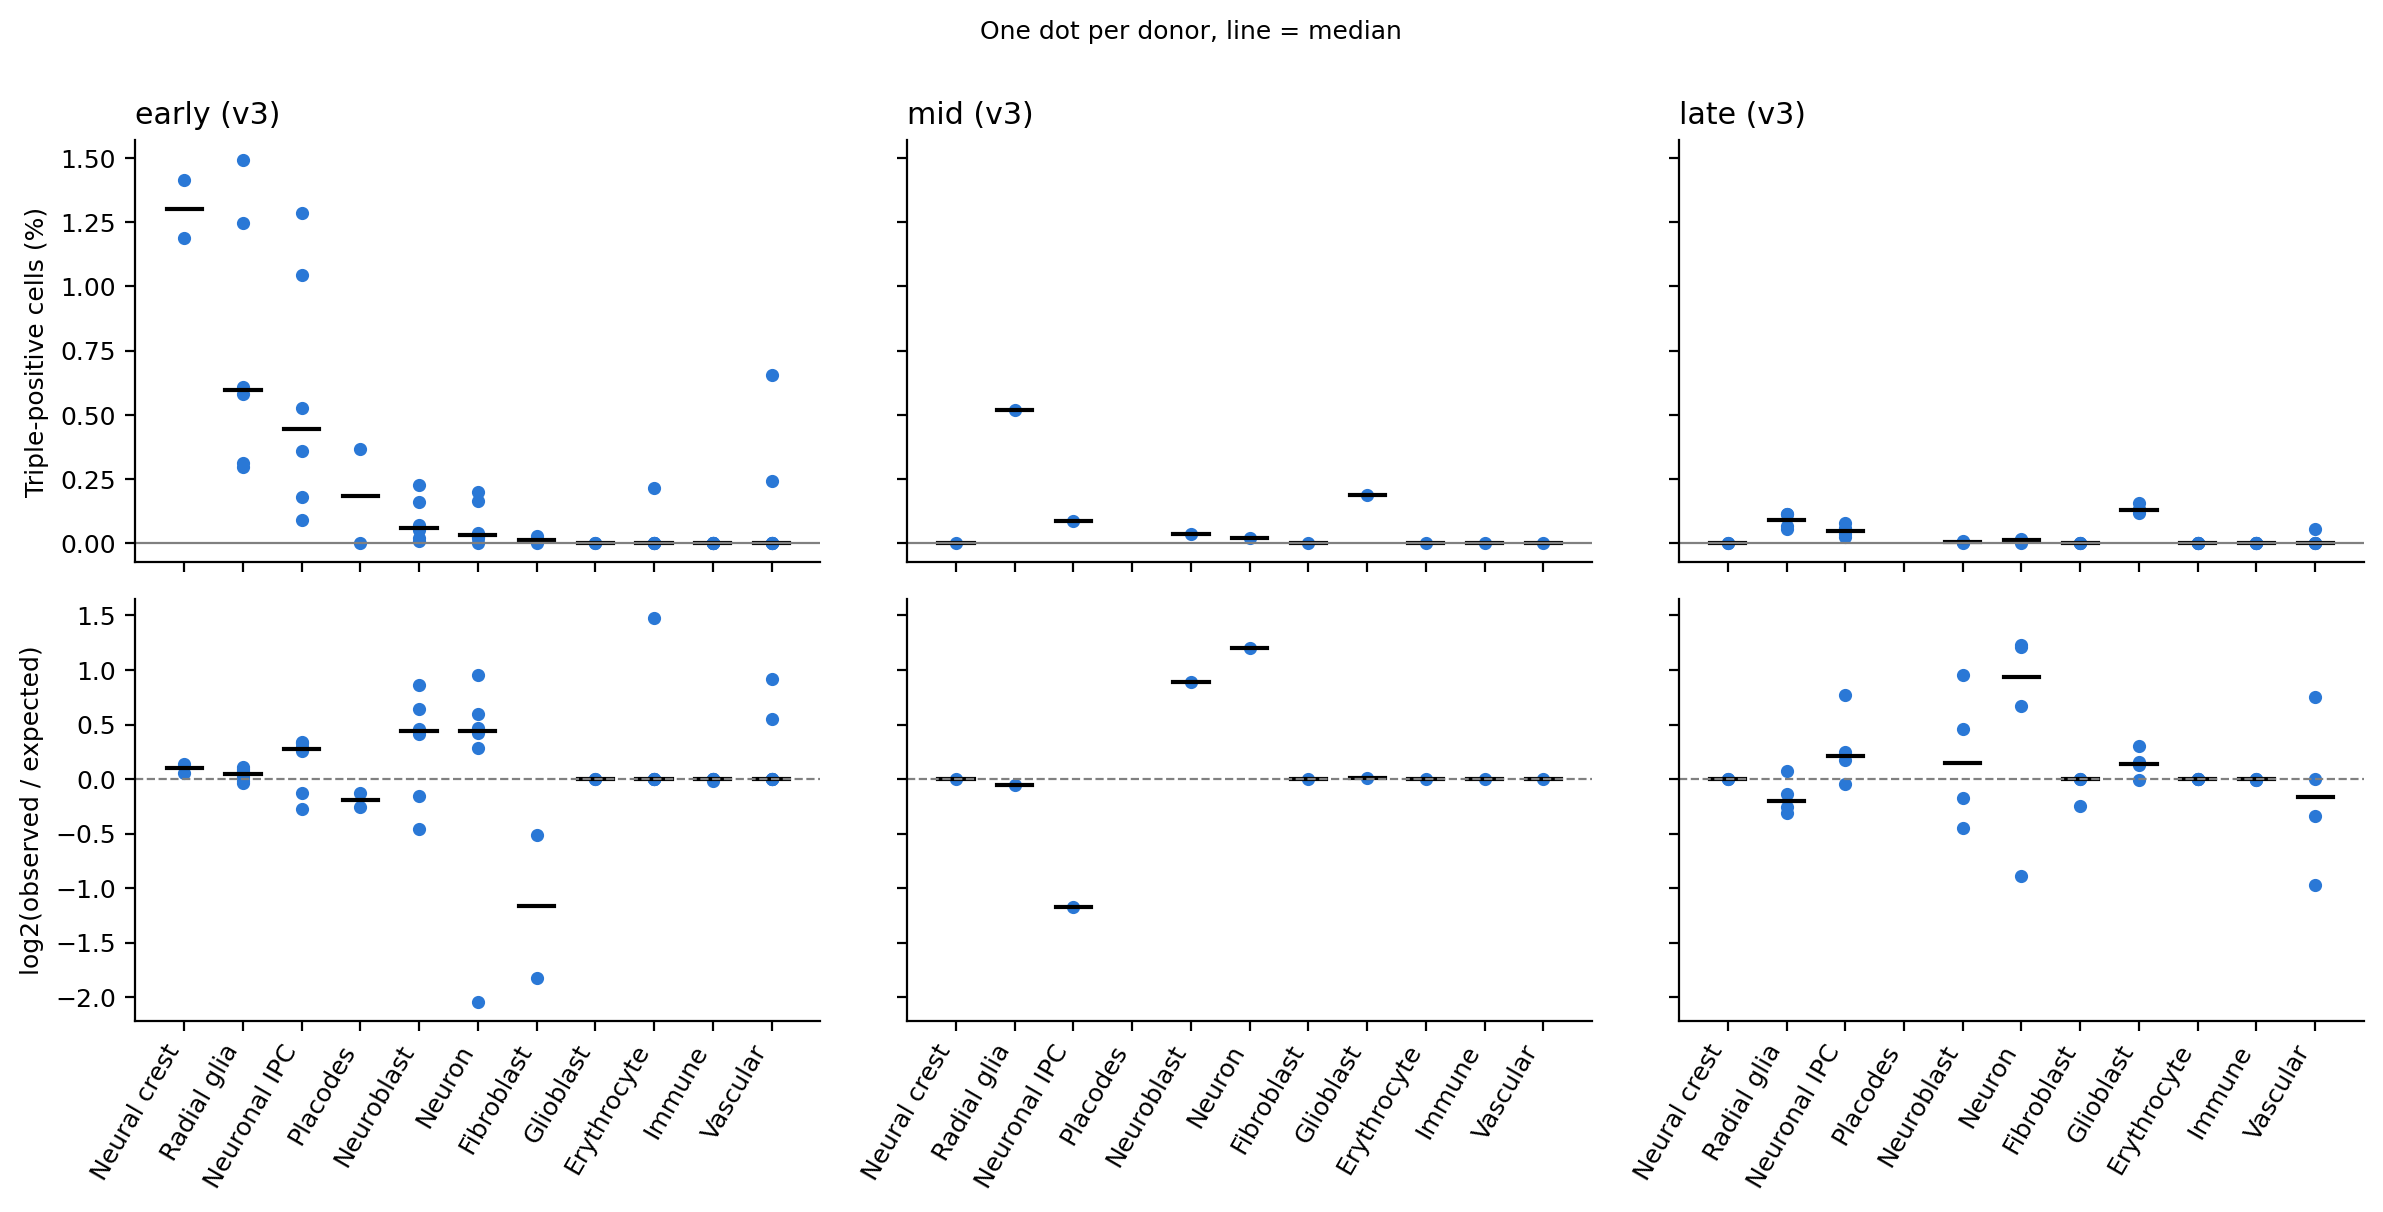

In [6]:
# Columns = age bins, top row = share of triple-positive cells, bottom row = log2(observed/expected).
# Cell classes keep the early-bin order in every panel so the bins are easy to compare.
order = summary.loc[BINS[0]].sort_values("triple_pct", ascending=False).index
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey="row")
for j, b in enumerate(BINS):
    for i, (col, label) in enumerate([("triple_pct", "Triple-positive cells (%)"),
                                      ("log2_oe", "log2(observed / expected)")]):
        ax = axes[i, j]
        for k, c in enumerate(order):
            y = v3.loc[(v3["age_bin"] == b) & (v3["cell_class"] == c), col]
            ax.scatter([k] * len(y), y, s=14, color="#2a78d6")
            ax.plot([k - 0.3, k + 0.3], [y.median()] * 2, color="black")
        ax.axhline(0, color="grey", linewidth=0.8, linestyle="--" if i else "-")
        ax.set_xticks(range(len(order)), order, rotation=60, ha="right")
        axes[i, 0].set_ylabel(label)
    axes[0, j].set_title(f"{b} (v3)", loc="left")
fig.suptitle("One dot per donor, line = median", y=1.0, fontsize=9)
fig.tight_layout()
save(fig, "05_coexpression_by_class")

**Reading the figure**

- **Early (left):** radial glia, neural crest and neuronal IPC have the most triple-positive cells. Donors
  vary: radial glia range from about 0.3% to 1.5%, so the effect is clear but differs between embryos.
- **Mid:** only one v3 donor (8.5 weeks), so each class is a single dot. Its radial glia are still at about
  0.5%, close to early.
- **Late:** almost everything drops. Late radial glia are at about 0.1%, following the loss of LIN28A
  (step 04).
- **Bottom row:** radial glia stay close to 0 in all bins, so their co-expression is about what chance
  predicts. The larger positive and negative values belong to classes with very few triple-positive cells,
  where one or two cells change the ratio a lot.

## Figure: clusters with the most triple-positive cells

**What this cell does**

- `top`: the 25 clusters (with at least 500 v3 cells) with the highest triple-positive share. `.iloc[::-1]`
  reverses the order so the highest is drawn at the top of the bar chart.
- `ax.barh`: horizontal bars, orange for selected clusters and grey for the rest (`np.where` picks the colour).
- Each bar is labelled with cluster ID, cell class, region and median age.
- `ax.axvline`: the dashed line at the cutoff, 5 x background.

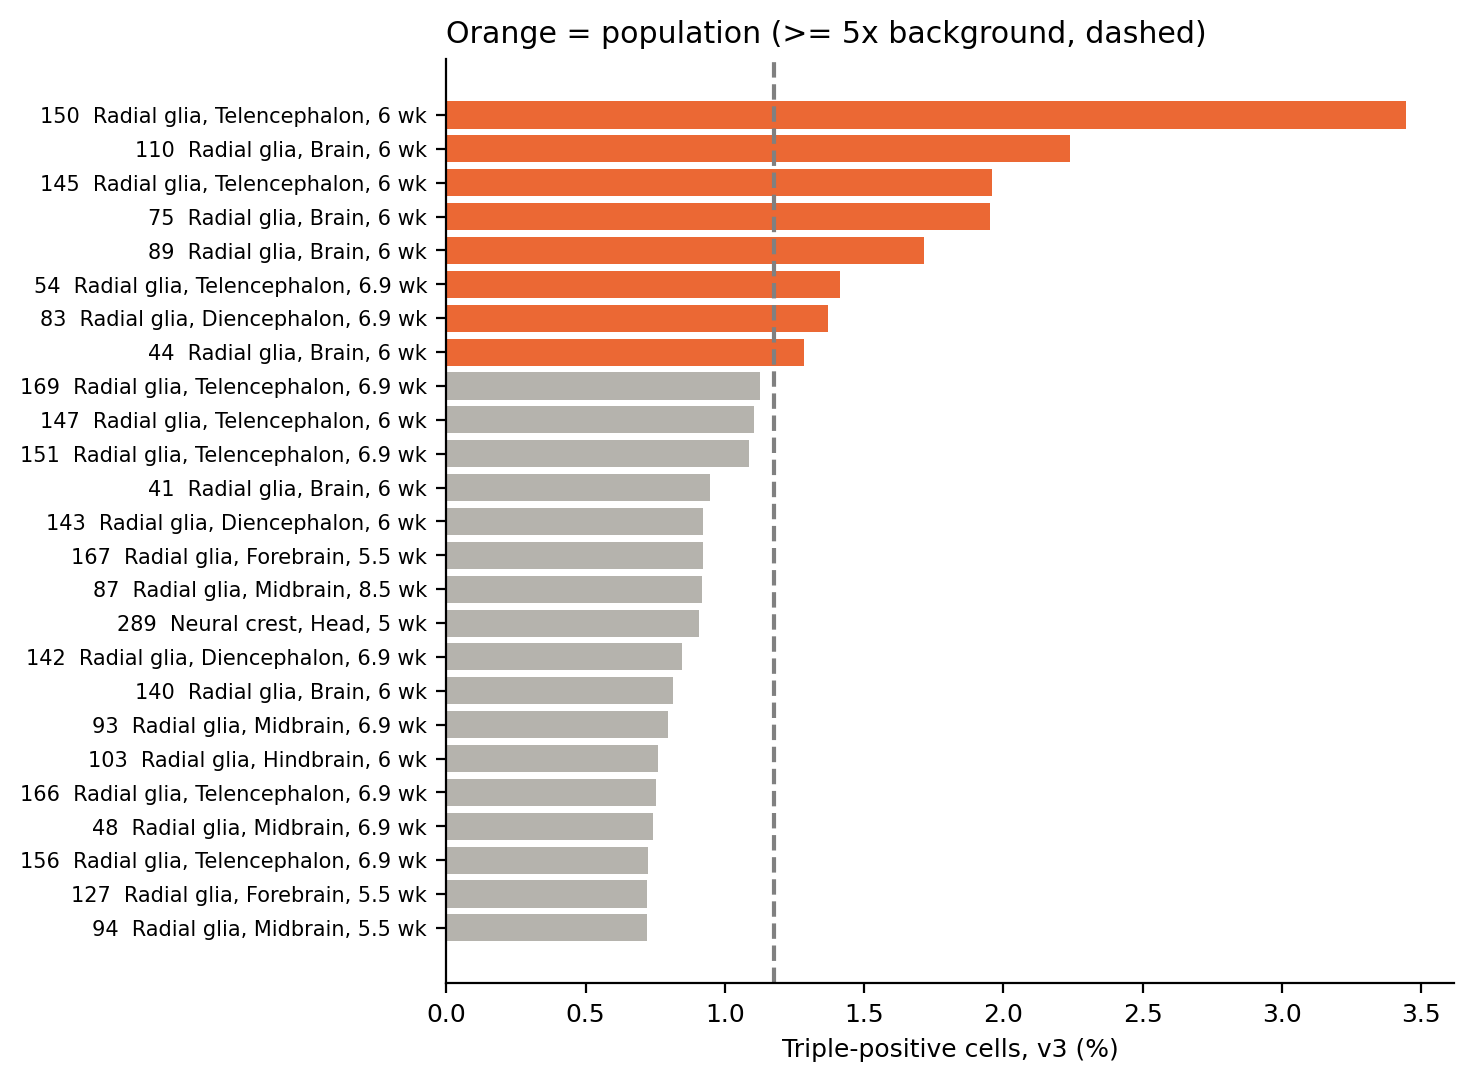

In [7]:
# Top 25 clusters; orange bars are the selected population, the dashed line is the cutoff
top = clusters[clusters["cells"] >= POP["min_cells"]].head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.barh(range(len(top)), top["triple"] * 100, color=np.where(top["selected"], "#eb6834", "#b5b3ad"))
ax.set_yticks(range(len(top)), [f"{i}  {r.cell_class}, {r.region}, {r.age:g} wk" for i, r in top.iterrows()],
              fontsize=7.5)
ax.axvline(POP["fold"] * background * 100, color="grey", linestyle="--")
ax.set_xlabel("Triple-positive cells, v3 (%)")
ax.set_title(f"Orange = population (>= {POP['fold']}x background, dashed)", loc="left")
save(fig, "05_population_clusters")

**Reading the figure**

- All 8 selected clusters are **radial glia at 6 to 6.9 weeks**, from telencephalon, diencephalon and
  whole-brain samples. The top cluster (150, telencephalon, 6 weeks) has 3.45% triple-positive cells, about
  15 times the background.
- The clusters just below the cutoff are also early radial glia (5.5 to 6.9 weeks, plus one at 8.5 weeks)
  and one neural crest cluster. So there is no sharp boundary: the population is the most enriched end of a
  broader early radial glia state.
- Even in the top cluster, only about 3% of cells are triple-positive. The population is a cell state where
  co-expression is most frequent, not a group in which every cell co-expresses the three genes.

## Figure: triple-positive cells and the population on the authors' map

**What the map is:** the
authors computed a 2D layout of all cells (`X_Embedding` in the h5ad, similar to a UMAP). Cells with similar
expression lie close together, so each island is roughly one cell type.

**What this cell does**

- `xy`: the 2D position of every cell.
- Two panels: left highlights the triple-positive cells, right the population cells.
- `ax.scatter(*xy[~mask].T, ...)`: all other cells in light grey first (`~mask` means "not highlighted"),
  then the highlighted cells in orange on top, so they are visible.
- `s=0.05` makes the 1.67 million grey dots tiny; `rasterized=True` stores the dots as an image inside the
  figure, which keeps the file small.
- `ax.axis("off")`: the axes of such a map have no meaning, so they are hidden.

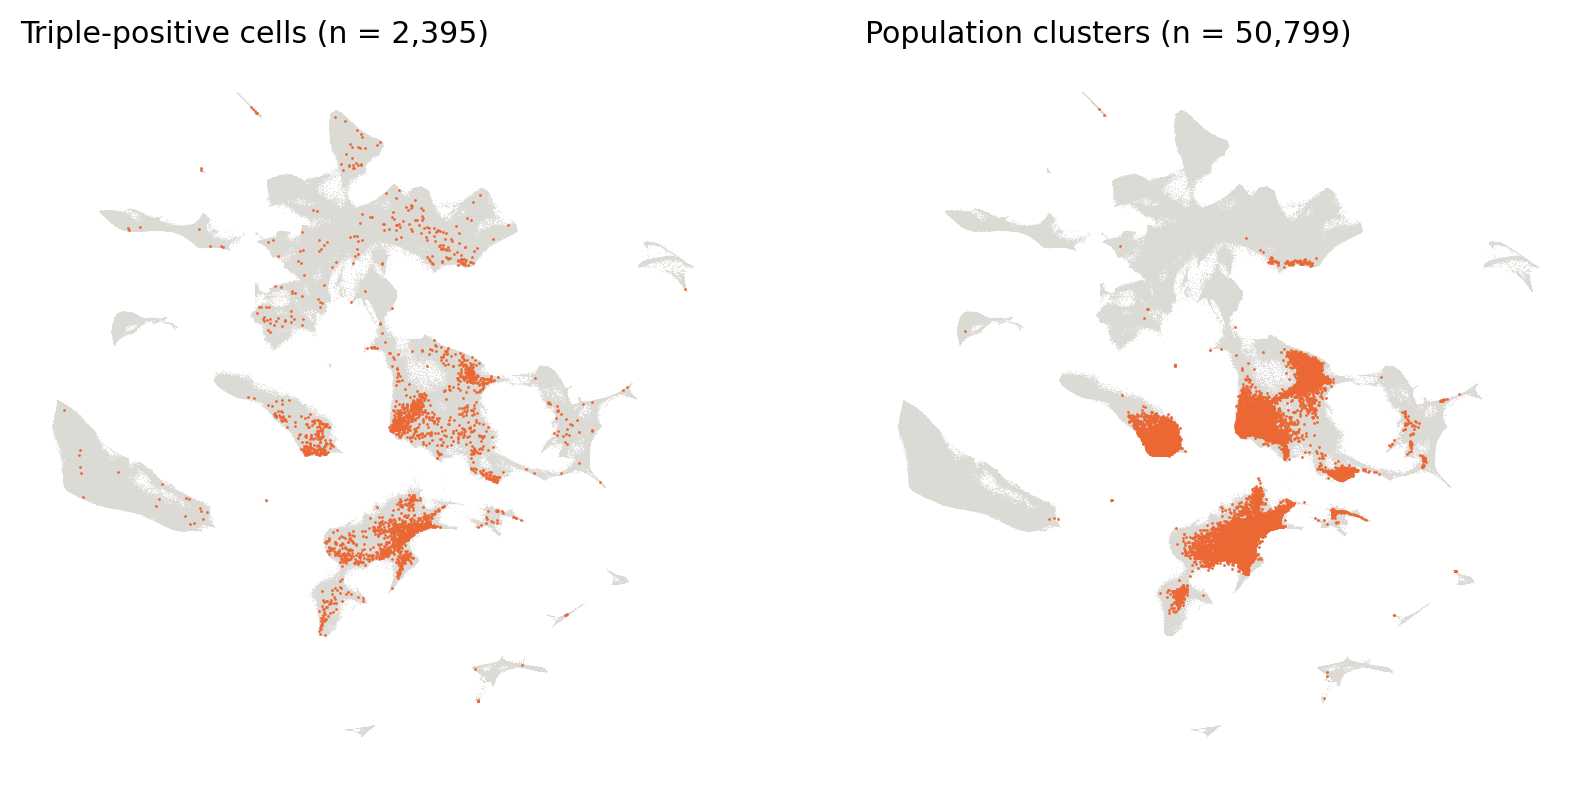

In [8]:
# Grey = all other cells, orange = highlighted cells. Shows where the population sits in the atlas.
xy = np.asarray(adata.obsm["X_Embedding"])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, mask, title in [(axes[0], cells["triple"].to_numpy(), "Triple-positive cells"),
                        (axes[1], in_pop.to_numpy(), "Population clusters")]:
    ax.scatter(*xy[~mask].T, color="#dcdad5", s=0.05, linewidths=0, rasterized=True)
    ax.scatter(*xy[mask].T, color="#eb6834", s=1, linewidths=0, rasterized=True)
    ax.set_title(f"{title} (n = {mask.sum():,})", loc="left")
    ax.axis("off")
save(fig, "05_embedding")

**Reading the figure**

- **Left:** the 2,395 triple-positive cells cluster in a few islands (the radial glia regions of the map) and
  are scattered thinly elsewhere.
- **Right:** the 50,799 population cells cover the densest of these areas. The population is where
  triple-positive cells concentrate, which confirms the cluster choice visually.

## Conclusion of step 05 (answer to question 1)

1. Triple-positive cells (all three genes at least 1 UMI) are rare: 0.235% of v3 cells, 2,395 cells in total.
2. They are most frequent in **early (5 to 7 weeks) radial glia**, followed by neural crest and neuronal
   intermediate progenitors. They almost disappear by 10 to 14 weeks, following the loss of LIN28A.
3. In radial glia the co-expression is about what chance predicts (log2 observed/expected near 0). The three
   genes appear together because TTYH1 and NES are common there and LIN28A is still on, not because of a
   separate subset where they are switched on together.
4. **Population for question 2:** 8 radial glia clusters at 6 to 6.9 weeks with at least 5 times the
   background rate, 50,799 cells. Steps 06 and 07 find the genes that mark this state against other cell
   types (cell-type axis) and against later radial glia (stage axis).